# CORRECCIÓN DEL EXAMEN 2

| Nombre | Fecha | Expediente |
| :- | :- | :- |
| Carlos Enrique Nieves Ochoa | 16 de noviembre de 2026 | 758210 |

## EJERCICIO 1. Optimización

Se tiene la siguiente función

$$ f(x, y, z) = 30 - x^2 - y^2 - z^2 + 10\cos(2\pi x) + 10\cos(2\pi y) + 10\cos(2\pi z) $$

con dominio $(x, y, z) \in [-5.12, 5.12]^3$. Utiliza optimización bayesiana para encontrar el valor máximo empezando con 5 muestras aleatorias dentro del dominio, con 10 pasos adicionales de exploración y después maximizando.

Defino la función y armo los puntos candidatos con tres ciclos, uno por variable, porque el proceso gaussiano necesita una rejilla del dominio para predecir dónde pedir el siguiente punto.

In [27]:
#Librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import LogisticRegression
from scipy.stats import norm

In [28]:
def f(x, y, z):
    return 30 - x**2 - y**2 - z**2 + 10*np.cos(2*np.pi*x) + 10*np.cos(2*np.pi*y) + 10*np.cos(2*np.pi*z)

# 41 valores por eje, de 0.256 en 0.256, para que el 0 quede dentro de la rejilla
candidatos = []
for a in np.linspace(-5.12, 5.12, 41):
    for b in np.linspace(-5.12, 5.12, 41):
        for c in np.linspace(-5.12, 5.12, 41):
            candidatos.append([a, b, c])
P_new = np.array(candidatos)
print("Puntos candidatos:", P_new.shape)

Puntos candidatos: (68921, 3)


Quedan 68,921 puntos candidatos (41 por eje). Ahora saco las 5 muestras aleatorias dentro del dominio y fijo la semilla para que el resultado no cambie cada vez que corro el notebook.

In [29]:
np.random.seed(42)
x_ini = np.random.uniform(-5.12, 5.12, 5)
y_ini = np.random.uniform(-5.12, 5.12, 5)
z_ini = np.random.uniform(-5.12, 5.12, 5)

# P es una lista de [x, y, z] y valores guarda f en cada punto
P = []
valores = []
for i in range(5):
    P.append([x_ini[i], y_ini[i], z_ini[i]])
    valores.append(f(x_ini[i], y_ini[i], z_ini[i]))
    print(f"Muestra {i+1}: x = {P[i][0]:.4f}, y = {P[i][1]:.4f}, z = {P[i][2]:.4f}, f = {valores[-1]:.4f}")

Muestra 1: x = -1.2847, y = -3.5226, z = -4.9092, f = -11.8058
Muestra 2: x = 4.6153, y = -4.5252, z = 4.8119, f = -48.5050
Muestra 3: x = 2.3756, y = 3.7496, z = 3.4042, f = -16.6558
Muestra 4: x = 1.0103, y = 1.0354, z = -2.9456, f = 48.3856
Muestra 5: x = -3.5224, y = 2.1307, z = -3.2581, f = -1.1580


La mejor muestra inicial ya da 48.39, en un punto cercano a (1, 1, -3), y las otras cuatro salen negativas o casi en cero.

En los 10 pasos de exploración ajusto el proceso gaussiano con lo que llevo y pido el punto donde la desviación estándar de la predicción es más grande, sin fijarme todavía en qué tan alto sale el valor.

In [30]:
kernel = 1.0*RBF(length_scale=1.0)

# 10 pasos de exploración
for i in range(10):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(np.array(P), valores)
    y_pred, desv = gp.predict(P_new, return_std=True)

    p_sig = P_new[np.argmax(desv)]
    P.append([p_sig[0], p_sig[1], p_sig[2]])
    valores.append(f(p_sig[0], p_sig[1], p_sig[2]))
    print(f"Exploración {i+1}: x = {p_sig[0]:.3f}, y = {p_sig[1]:.3f}, z = {p_sig[2]:.3f}, f = {valores[-1]:.4f}")

Exploración 1: x = -5.120, y = -5.120, z = -5.120, f = -26.7741
Exploración 2: x = -5.120, y = -3.584, z = 5.120, f = -29.3337
Exploración 3: x = -5.120, y = 5.120, z = 5.120, f = -26.7741
Exploración 4: x = 5.120, y = -5.120, z = -2.560, f = -23.7008
Exploración 5: x = 5.120, y = 5.120, z = -5.120, f = -26.7741
Exploración 6: x = -0.512, y = -5.120, z = 1.024, f = 9.6795
Exploración 7: x = -2.304, y = 0.512, z = 2.304, f = 2.4930
Exploración 8: x = 5.120, y = -0.512, z = 0.768, f = 1.3803
Exploración 9: x = -5.120, y = -2.816, z = -0.512, f = -3.0592
Exploración 10: x = 5.120, y = -0.512, z = -5.120, f = -18.0832


Veo que la exploración se va primero a las esquinas del dominio, donde no había ninguna muestra, y por eso casi todos los valores salen negativos (cerca de -27 en las esquinas). Después se mete al centro y ahí aparecen valores un poco más altos, como 9.68 en (-0.512, -5.12, 1.024).

Ya con los 15 puntos empiezo a maximizar y en cada paso pido el punto con el límite superior más alto (`y_pred + 2*desv`), así no me quedo solo con la predicción y también tomo en cuenta las zonas donde todavía no sé bien cuánto vale f.

In [31]:
# Yo voy a usar 30 pasos de maximización
for i in range(30):
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)
    gp.fit(np.array(P), valores)
    y_pred, desv = gp.predict(P_new, return_std=True)

    p_sig = P_new[np.argmax(y_pred + 2*desv)]
    P.append([p_sig[0], p_sig[1], p_sig[2]])
    valores.append(f(p_sig[0], p_sig[1], p_sig[2]))
    print(f"Maximización {i+1}: x = {p_sig[0]:.3f}, y = {p_sig[1]:.3f}, z = {p_sig[2]:.3f}, f = {valores[-1]:.4f}")

Maximización 1: x = 0.768, y = 1.536, z = -1.792, f = 17.8313
Maximización 2: x = 1.024, y = 1.024, z = -2.816, f = 43.7751
Maximización 3: x = 0.512, y = 1.536, z = -3.328, f = -8.1209
Maximización 4: x = 1.280, y = 1.024, z = -3.072, f = 34.8826
Maximización 5: x = 1.024, y = 0.768, z = -3.072, f = 38.9335
Maximización 6: x = 0.768, y = 1.024, z = -2.816, f = 35.4759
Maximización 7: x = 1.024, y = 1.280, z = -2.816, f = 31.4249
Maximización 8: x = 1.024, y = 1.024, z = -3.328, f = 31.8933
Maximización 9: x = 0.768, y = 1.024, z = -3.072, f = 38.9335
Maximización 10: x = 1.024, y = 1.024, z = -3.072, f = 47.2328
Maximización 11: x = 1.024, y = 0.768, z = -2.816, f = 35.4759
Maximización 12: x = 1.024, y = 1.024, z = -3.072, f = 47.2328
Maximización 13: x = -5.120, y = -5.120, z = -4.864, f = -24.9421


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 11 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 12 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 5 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/s

Maximización 14: x = 1.024, y = 1.024, z = -3.072, f = 47.2328
Maximización 15: x = -5.120, y = -5.120, z = -4.608, f = -36.8677


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessin

Maximización 16: x = -5.120, y = -5.120, z = -4.352, f = -32.7684
Maximización 17: x = -5.120, y = -5.120, z = -4.096, f = -16.3913


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessin

... (12 outputs left out)

Maximización 26: x = -5.120, y = -5.120, z = -2.560, f = -23.7008
Maximización 27: x = 1.024, y = 1.024, z = -3.072, f = 47.2328
Maximización 28: x = -5.120, y = -5.120, z = -2.304, f = -16.4860


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 6 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


Maximización 29: x = -5.120, y = -5.120, z = -2.048, f = -2.4951
Maximización 30: x = 1.024, y = 1.024, z = -3.072, f = 47.2328


c:\Users\carlo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\gaussian_process\_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 14 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


En los primeros 12 pasos el proceso se mueve alrededor de (1, 1, -3), con valores de -8.12 a 47.23, y el más alto lo da (1.024, 1.024, -3.072). Después va alternando entre ese punto y la esquina (-5.12, -5.12, z), donde todavía había mucha incertidumbre, y ahí los valores salen negativos (de -36.87 a -8.29).

Mejor punto: x = 1.010262878177655  y = 1.0354177202504582  z = -2.9456475066544523
Valor máximo encontrado: 48.38557598813463


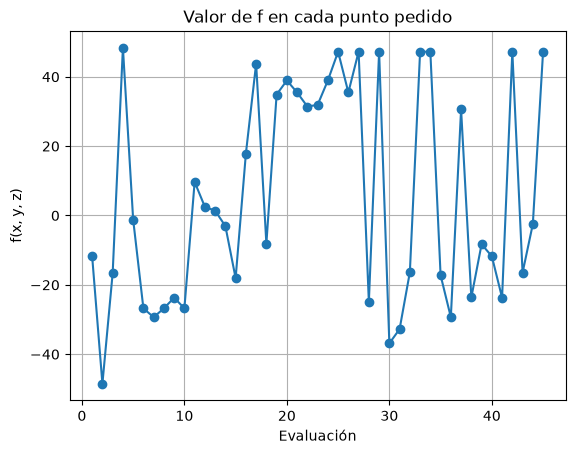

,x,y,z,"f(x, y, z)"
0,-1.2847,-3.5226,-4.9092,-11.8058
1,4.6153,-4.5252,4.8119,-48.5050
2,2.3756,3.7496,3.4042,-16.6558
3,1.0103,1.0354,-2.9456,48.3856
4,-3.5224,2.1307,-3.2581,-1.1580
5,-5.1200,-5.1200,-5.1200,-26.7741
6,-5.1200,-3.5840,5.1200,-29.3337
7,-5.1200,5.1200,5.1200,-26.7741
8,5.1200,-5.1200,-2.5600,-23.7008
9,5.1200,5.1200,-5.1200,-26.7741


In [32]:
resultados = pd.DataFrame(P, columns=["x", "y", "z"])
resultados["f(x, y, z)"] = valores

print("Mejor punto: x =", P[np.argmax(valores)][0], " y =", P[np.argmax(valores)][1], " z =", P[np.argmax(valores)][2])
print("Valor máximo encontrado:", max(valores))

plt.figure()
plt.plot(range(1, len(valores) + 1), valores, marker="o")
plt.xlabel("Evaluación")
plt.ylabel("f(x, y, z)")
plt.title("Valor de f en cada punto pedido")
plt.grid()
plt.show()

resultados.round(4)

El valor máximo que encuentro es 48.39 en (1.010, 1.035, -2.946), que viene de una de las muestras iniciales, y en la maximización lo más alto es 47.23 en (1.024, 1.024, -3.072), el punto de la rejilla más cercano a esa muestra. El máximo real de la función es 60 en (0, 0, 0), así que con 45 evaluaciones no lo alcanzo, porque la función tiene un máximo local en cada combinación de enteros y el proceso gaussiano se quedó buscando alrededor del de (1, 1, -3).

### **Preguntas**

#### **¿Cuál fue el error?**

No usé optimización bayesiana. Mi código no tenía `GaussianProcessRegressor`, los 10 pasos de exploración eran otros 10 puntos al azar y la maximización sorteaba 100 puntos por paso y los evaluaba con la función real, o sea que hacía 1,000 evaluaciones de f y era búsqueda aleatoria. Tampoco fijé la semilla, así que el resultado cambiaba cada vez que corría la celda.

#### **¿Cuál es la corrección?**

Ajustar el proceso gaussiano con los puntos que llevo y usarlo para decidir el siguiente punto, en los primeros 10 pasos con el de mayor desviación estándar (`np.argmax(desv)`) y después con el de mayor límite superior (`np.argmax(y_pred + 2*desv)`). Así solo evalúo f en los puntos que pide el modelo, 45 en total.

#### **¿Por qué se cometió el error?**

Sinceramente, esa semana se me juntaron cuatro exámenes y se me dificultó estudiar, así que terminé aceptando la recomendación de GitHub Copilot y por los tiempos no me fijé en el método hasta después cuando revisé el examen.

#### **¿Cómo puedo evitar este error en el futuro?**

Antes de aceptar una sugerencia de código puedo revisar que tenga las piezas del método que pide la pregunta, en este caso `GaussianProcessRegressor`, `gp.fit`, `gp.predict` y el `np.argmax` que elige el siguiente punto, y si falta alguna la descarto y lo escribo yo. También puedo llevar en mis notas un esqueleto de código de cada tema, porque normalmente no las llevo, y en el de optimización bayesiana dejar los pasos en orden (muestras iniciales, ajustar el proceso gaussiano, elegir el punto con mayor desviación para explorar y el de mayor límite superior para maximizar) para guiarme al resolver el ejercicio.

## **EJERCICIO 2. Clasificación**

Un productor quiere saber si el hecho de que una película sea comedia o no, y el año en que salió, tiene un peso sobre si la película es considerada buena (calificación mayor a 7.5), con los datos de `reviews_peliculas.csv`.

### Revisión del dataset

Cargo el archivo y reviso tipos, faltantes, duplicados y los valores de las dos columnas de texto que necesito para el modelo.

In [33]:
df = pd.read_csv("reviews_peliculas.csv")
print("Tamaño:", df.shape)
print(df.dtypes)
print(df.isna().sum())
print("Duplicados:", df.duplicated().sum())

for col in ["genero", "anio_estreno"]:
    print(col, "->", df[col].unique())

Tamaño: (240, 5)
titulo                      str
genero                      str
anio_estreno                str
presupuesto_millones_usd    str
calificacion_publico        str
dtype: object
titulo                      0
genero                      0
anio_estreno                0
presupuesto_millones_usd    3
calificacion_publico        2
dtype: int64
Duplicados: 0
genero -> <ArrowStringArray>
['Ciencia ficción',           'Drama',         'Comedia',          'Terror',
      'Documental',          'Acción',         ' drama ',       'Animación',
 'CIENCIA FICCION',         'Romance',         'comedia',          'Accion',
         'Terrorr',        'Fantasia',         'romance']
Length: 15, dtype: str
anio_estreno -> <ArrowStringArray>
['2011', '2024', '2009', '2023', '2020', '2015', '2019', '2001', '2007',
 '2012', '2022', '2016', '2000', '2005', '2004', '2003', '2008', '2010',
 '2014', '2002', '2006', '2017', '2021', '2013', '2018', '20O8']
Length: 26, dtype: str


Todas las columnas vienen como texto, hay 3 presupuestos y 2 calificaciones faltantes y no hay duplicados. En `genero` la misma categoría aparece escrita de varias formas (" drama ", "CIENCIA FICCION", "comedia", "Accion", "Terrorr", "Fantasia", "romance") y en `anio_estreno` hay un "20O8" con letra O.

### Limpieza

Cambio la coma decimal por punto en el presupuesto y la calificación, corrijo el año escrito con O y convierto las tres columnas a número.

In [ ]:
df["presupuesto_millones_usd"] = df["presupuesto_millones_usd"].str.replace(",", ".", regex=False).astype(float)
df["calificacion_publico"] = df["calificacion_publico"].str.replace(",", ".", regex=False).astype(float)

anio = df["anio_estreno"]
anio.loc[anio == "20O8"] = "2008"
df["anio_estreno"] = anio.astype(int)

print(df.dtypes)

titulo                          str
genero                          str
anio_estreno                  int64
presupuesto_millones_usd    float64
calificacion_publico        float64
dtype: object


Paso el género a minúsculas, le quito los espacios y uno las variantes mal escritas con su categoría.

In [35]:
gen = df["genero"].str.lower()
gen = gen.str.strip()
gen.loc[gen == "accion"] = "acción"
gen.loc[gen == "ciencia ficcion"] = "ciencia ficción"
gen.loc[gen == "terrorr"] = "terror"
gen.loc[gen == "fantasia"] = "fantasía"
df["genero"] = gen

print(df["genero"].value_counts())

genero
drama              41
acción             40
comedia            39
ciencia ficción    36
terror             27
romance            24
documental         20
animación          12
fantasía            1
Name: count, dtype: int64


Quedan nueve géneros, con 39 comedias. Fantasía tiene una sola película pero la dejo porque es un género válido y para el modelo solo importa si es comedia o no.

In [ ]:
df["presupuesto_millones_usd"] = df["presupuesto_millones_usd"].fillna(df["presupuesto_millones_usd"].median())

df = df.dropna()

print(df.isna().sum())
print("Tamaño:", df.shape)

titulo                      0
genero                      0
anio_estreno                0
presupuesto_millones_usd    0
calificacion_publico        0
dtype: int64
Tamaño: (238, 5)


Relleno el presupuesto con la mediana, aunque no entra al modelo, y quito las 2 películas sin calificación porque de esa columna sale la respuesta y rellenarla sería inventar si la película es buena. Quedan 238 películas sin faltantes.

### **Preguntas**

#### **¿Cuál fue el error?**

Dejé la limpieza a medias. Usé `fillna(..., inplace=True)` sobre una columna y pandas avisó con un `ChainedAssignmentError` que el cambio se hacía sobre una copia, así que los faltantes se quedaron. Tampoco corregí las categorías de `genero` ni el año "20O8", y `anio_estreno` siguió como texto.

#### **¿Cuál es la corrección?**

Asignar el resultado de vuelta a la columna, `df["col"] = df["col"].fillna(...)`, unificar el género con minúsculas, `strip` y los reemplazos de las variantes, corregir el "20O8" y convertir el año a entero. La calificación faltante la quito en lugar de rellenarla porque define la respuesta.

#### **¿Por qué se cometió el error?**

Se me acabó el tiempo, y al principio creí que solo tenía que limpiar las variables numéricas. Al revisar bien el examen me di cuenta de que también tenía que limpiar las categóricas, pero ya no me dio tiempo de seguir.

#### **¿Cómo puedo evitar este error en el futuro?**

Al empezar puedo anotar qué columnas usa la pregunta (aquí género, año y calificación) y limpiar esas primero, revisando el `unique()` de cada una aunque parezca numérica, porque el "20O8" estaba en el año. Después de cada celda de limpieza corro `df.isna().sum()` y `df.dtypes` para confirmar que el cambio sí se aplicó, y no uso `inplace=True`, siempre asigno el resultado a la columna.

### **Variable de respuesta y comedia**

Creo la respuesta con las películas de calificación mayor a 7.5 y una variable que vale 1 si la película es comedia.

buena
0    230
1      8
Name: count, dtype: int64
comedia
0    200
1     38
Name: count, dtype: int64
Proporción de buenas en comedias: 0.10526315789473684
Proporción de buenas en las demás: 0.02


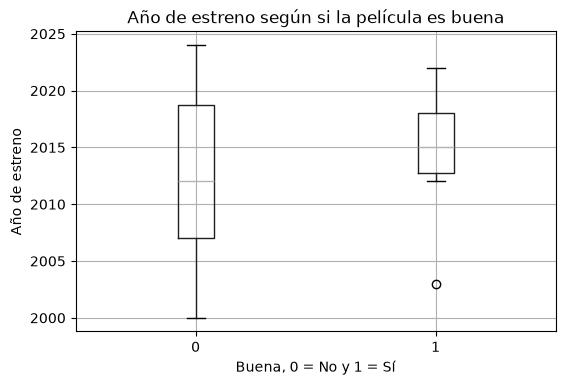

In [37]:
df["buena"] = (df["calificacion_publico"] > 7.5).astype(int)
df["comedia"] = (df["genero"] == "comedia").astype(int)

print(df["buena"].value_counts())
print(df["comedia"].value_counts())
print("Proporción de buenas en comedias:", df.loc[df["comedia"] == 1, "buena"].mean())
print("Proporción de buenas en las demás:", df.loc[df["comedia"] == 0, "buena"].mean())

df.boxplot(column="anio_estreno", by="buena", figsize=(6, 4))
plt.suptitle("")
plt.title("Año de estreno según si la película es buena")
plt.xlabel("Buena, 0 = No y 1 = Sí")
plt.ylabel("Año de estreno")
plt.show()

Solo 8 de las 238 películas son buenas (3.4%). De las comedias, el 10.5% son buenas, frente a 2% en los demás géneros, y en la gráfica veo que el año de las buenas va de 2003 a 2022, con mediana en 2015 frente a 2012 de las demás.

### **Regresión logística**

Ajusto la regresión logística con comedia y año, con `C` muy grande para que los coeficientes no queden penalizados.

In [38]:
X = df[["comedia", "anio_estreno"]]
y = df["buena"]

modelo = LogisticRegression(C=1000000, max_iter=1000, tol=1e-8)
modelo.fit(X, y)

beta = np.hstack([modelo.intercept_, modelo.coef_[0]])
print("Intercepto, comedia y año:", beta)

Intercepto, comedia y año: [-1.03237949e+02  1.75615356e+00  4.93398584e-02]


Calculo los errores estándar, el estadístico z y el p-value de cada coeficiente para saber si su peso es significativo.

In [39]:
prob = modelo.predict_proba(X)[:, 1]
w = prob * (1 - prob)
V = np.diagflat(w)

# La columna de unos corresponde al intercepto
X_diseno = np.hstack([np.ones((len(X), 1)), X.values])
cov = np.linalg.inv(X_diseno.T @ V @ X_diseno)
se = np.sqrt(np.diag(cov))

z_statistic = beta / se
p_value = 2 * (1 - norm.cdf(abs(z_statistic)))

tabla = pd.DataFrame({
    "Coeficiente": beta,
    "Error estándar": se,
    "z": z_statistic,
    "p-value": p_value
}, index=["Intercepto", "comedia", "anio_estreno"])

tabla

,Coeficiente,Error estándar,z,p-value
Intercepto,-103.237949,103.339582,-0.999017,0.317787
comedia,1.756154,0.734072,2.392346,0.016741
anio_estreno,0.049340,0.051293,0.961913,0.336094


El coeficiente de comedia es positivo (1.76) y su p-value es 0.017, así que con 5% de significancia ser comedia sí tiene peso y aumenta la probabilidad de que la película sea buena. El año tiene un coeficiente de 0.049 con p-value de 0.336, por lo que no encuentro evidencia de que el año de estreno influya.

Al productor le diría que en estos datos las comedias tienen más probabilidad de ser buenas y que el año no importa, pero se debe tomar con cuidado porque solo tenemos 8 películas buenas y 4 de ellas son comedias, así que una o dos películas más podrían cambiar el resultado.

### **Preguntas**

#### **¿Cuál fue el error?**

No llegué al modelo. Nunca creé la variable de película buena ni la de comedia, no ajusté la regresión logística y no contesté la pregunta del productor.

#### **¿Cuál es la corrección?**

Crear la respuesta con `calificacion_publico > 7.5`, la variable de comedia con el género ya limpio, ajustar la regresión logística con comedia y año y revisar los p-values para decir cuál de los dos factores tiene peso.

#### **¿Por qué se cometió el error?**

Se me acabó el tiempo en la limpieza y no llegué a esta parte.

#### **¿Cómo puedo evitar este error en el futuro?**

Al empezar el examen puedo escribir en celdas vacías los comentarios de todos los pasos hasta la respuesta final (limpiar, crear la respuesta, crear comedia, ajustar el modelo, p-values, conclusión) y darle un tiempo a cada uno. Si la limpieza se alarga, sigo con las columnas que ya quedaron limpias para llegar al modelo y regreso después a lo que falte.